In [160]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [161]:

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["Species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

print("Dataset loaded successfully!")
print("Total Samples:", len(df))
print("Total Features:", len(iris.feature_names))
print("Species:", list(iris.target_names))

df.head()

Dataset loaded successfully!
Total Samples: 150
Total Features: 4
Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [162]:
# Preview the first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


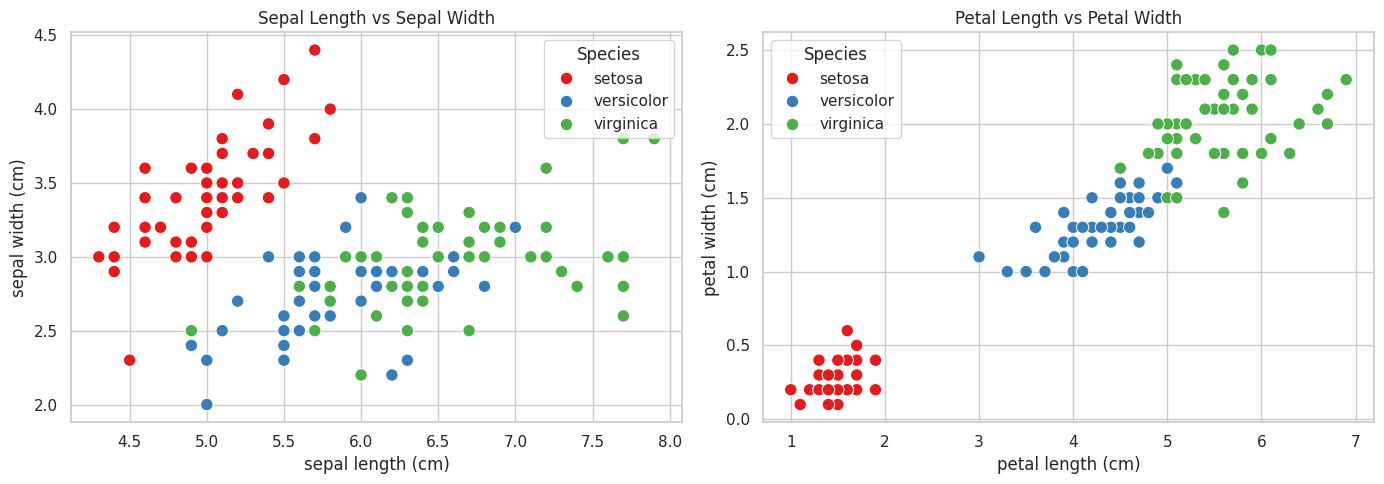

In [163]:

# Iris Flower Scatter Charts

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Sepal measurements
sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="sepal width (cm)",
    hue="Species",
    palette="Set1",
    s=80,
    ax=axes[0]
)
axes[0].set_title("Sepal Length vs Sepal Width")

# Chart 2: Petal measurements
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Species",
    palette="Set1",
    s=80,
    ax=axes[1]
)
axes[1].set_title("Petal Length vs Petal Width")

plt.tight_layout()
plt.show()

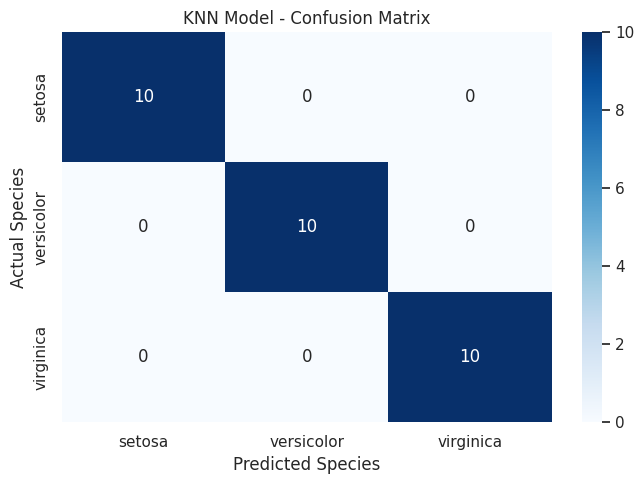

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [164]:

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN Model - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# Display classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

In [165]:

!pip -q install gradio

In [166]:

import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Scatter chart 1: Sepal measurements
def sepal_scatter():
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(
        data=df,
        x="sepal length (cm)",
        y="sepal width (cm)",
        hue="Species",
        palette="Set1",
        s=70,
        ax=ax
    )
    ax.set_title("Sepal Length vs Sepal Width")
    fig.tight_layout()
    return fig

# Scatter chart 2: Petal measurements
def petal_scatter():
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(
        data=df,
        x="petal length (cm)",
        y="petal width (cm)",
        hue="Species",
        palette="Set1",
        s=70,
        ax=ax
    )
    ax.set_title("Petal Length vs Petal Width")
    fig.tight_layout()
    return fig

# Confusion matrix
def make_confusion_matrix():
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )
    ax.set_title("KNN Confusion Matrix")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")
    fig.tight_layout()
    return fig

# Flower prediction
def predict_flower(sl, sw, pl, pw):
    sample = pd.DataFrame(
        [[sl, sw, pl, pw]],
        columns=iris.feature_names
    )
    pred = knn_model.predict(sample)[0]
    probs = knn_model.predict_proba(sample)[0]

    probability_dict = {
        iris.target_names[i]: float(probs[i])
        for i in range(3)
    }

    return iris.target_names[pred].title(), probability_dict

# Build dashboard
with gr.Blocks() as demo:
    gr.Markdown("""
    # 🌸 Iris Flower Classification Dashboard
    ### InfozaTech | Data Science Internship — Task 3
    Explore the dataset, model performance, and flower predictions.
    """)

    with gr.Row():
        gr.Number(value=len(df), label="Total Samples", interactive=False)
        gr.Number(value=4, label="Features", interactive=False)
        gr.Number(value=3, label="Species", interactive=False)
        gr.Number(
            value=round(accuracy * 100, 2),
            label="Model Accuracy (%)",
            interactive=False
        )

    with gr.Tab("Dataset"):
        gr.Markdown("### Preview of the Iris dataset")
        gr.Dataframe(value=df.head(10), interactive=False)
        gr.Markdown("### Samples by species")
        gr.BarPlot(
            value=df["Species"].value_counts()
                .rename_axis("Species")
                .reset_index(name="Count"),
            x="Species",
            y="Count",
            title="Species Distribution"
        )

    with gr.Tab("Visualizations"):
        gr.Markdown("### Sepal Scatter Chart")
        gr.Plot(value=sepal_scatter())

        gr.Markdown("### Petal Scatter Chart")
        gr.Plot(value=petal_scatter())

        gr.Markdown("### Model Confusion Matrix")
        gr.Plot(value=make_confusion_matrix())

    with gr.Tab("Predict a Flower"):
        gr.Markdown("Enter flower measurements in centimetres.")
        sl = gr.Slider(4.0, 8.0, value=5.1, label="Sepal length (cm)")
        sw = gr.Slider(2.0, 4.5, value=3.5, label="Sepal width (cm)")
        pl = gr.Slider(1.0, 7.0, value=1.4, label="Petal length (cm)")
        pw = gr.Slider(0.1, 2.5, value=0.2, label="Petal width (cm)")

        predict_btn = gr.Button("Predict Species")
        result = gr.Textbox(label="Predicted Species")
        probs = gr.Label(label="Prediction Probabilities")

        predict_btn.click(
            predict_flower,
            inputs=[sl, sw, pl, pw],
            outputs=[result, probs]
        )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c97f48b8c0d5964abc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [167]:

# Prepare features and target
X = df[iris.feature_names].copy()
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Make predictions
y_pred = knn_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Trained Successfully!")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

KNN Model Trained Successfully!
Model Accuracy: 100.00%
Training samples: 120
Testing samples: 30


In [168]:

sample_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = knn_model.predict(sample_flower)[0]

print("Predicted Flower Species:",
      iris.target_names[prediction].title())

Predicted Flower Species: Setosa


# InfozaTech — Task 3: Iris Flower Classification

## Objective

To classify iris flowers into three species using machine learning.

## Tools and Technologies

* Python
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn
* Gradio

## Work Completed

1. Loaded and explored the Iris dataset containing 150 samples.
2. Created scatter plots to visualize flower measurements.
3. Trained a K-Nearest Neighbors (KNN) classification model.
4. Evaluated model performance using accuracy and a confusion matrix.
5. Built an interactive dashboard to explore the dataset and predict flower species.

## Conclusion

The Iris Flower Classification project demonstrates how machine learning can classify flower species using sepal and petal measurements. The interactive dashboard makes it possible to explore the dataset and test predictions.
